# Camouflage-Aware Medical Image Segmentation — Stage 2 + Stage 3 (Paper-Ready)

**Stage 1 is NOT retrained here.** The camouflage teachers `CU1` / `CUA1` are loaded
read-only from Google Drive, because their logs show validation Dice peaking early
(best `0.4679`) and then *falling* to `0.3383` by epoch 30 while training loss kept
dropping — more Stage 1 epochs would only buy more overfitting.

## What this notebook changes versus the previous run

| Area | Before | Now | Why |
|---|---|---|---|
| Output paths | fixed filenames | run-scoped `camo_runs/<RUN_ID>/` | a rerun can no longer destroy earlier results |
| Checkpoint safety | `best_dice = -1` each run | refuses to overwrite unless `ALLOW_OVERWRITE` | an interrupted rerun used to replace good weights with epoch-1 weights |
| Augmentation | none | flip / rot90 / affine / colour jitter | the single biggest cause of the Stage 1 overfitting |
| LR schedule | constant `1e-4` | cosine annealing + early stopping | better convergence in a fixed 30-epoch budget |
| Kvasir split | 900 / 100, val used for BOTH selection and reporting | 800 / 100 / 100 with a held-out **test** split | reporting on the selection set is optimistically biased |
| Metrics | Dice, IoU averaged per *batch* | Dice, IoU, precision, recall, specificity, accuracy per *image* | correct averaging, and gives mean ± std error bars from ONE seed |
| Significance | none | paired Wilcoxon signed-rank, guided vs its own baseline | evidence that a delta is real, without paying for 3 seeds |
| Capacity control | none | `G1R` = guided UNet with a **random** frozen teacher | separates "camouflage pretraining helps" from "2x params helps" |
| Qualitative | none for Stage 2/3 | comparison grids, per-model PNGs, failure cases | required figures for the paper |
| Feature evidence | none | teacher / student / fused / \|fused − student\| maps | shows *why* guidance works |
| Efficiency | none | params, GMACs, GFLOPs, latency, FPS | answers "is the gain just extra capacity?" |
| Precision | fp32 | optional AMP | roughly 1.7–2x faster on a T4 |

## Run order

Sections 1 → 12 are setup and definitions. Section 13 trains Stage 2. Sections 14 → 20
produce every table and figure. Nothing after Section 13 retrains anything, so if the
kernel dies you can re-run Sections 1–12 and jump straight to Section 14.

> Set **Runtime → Change runtime type → GPU (T4)** before running.

## Section 1 — GPU check

In [ ]:
import sys, torch

print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA   :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))
    print("VRAM   : %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1024 ** 3))
else:
    print("WARNING: no GPU. Runtime -> Change runtime type -> GPU (T4).")

Python : 3.12.13
PyTorch: 2.11.0+cu128
CUDA   : True
GPU    : Tesla T4
VRAM   : 14.6 GB


## Section 2 — Dependencies

In [ ]:
!pip install -q kaggle tqdm matplotlib pandas scipy opencv-python-headless thop
print("Dependencies installed.")

Dependencies installed.


## Section 3 — Drive mount, run-scoped config

`RUN_ID` is the safety mechanism. Every checkpoint, CSV and figure produced below lives
under `camo_runs/<RUN_ID>/`, so a second run with a new `RUN_ID` cannot touch the first
one's results. Change `RUN_ID` whenever you change anything you might want to compare.

Stage 1 paths are opened **read-only** — this notebook never writes to them.

In [ ]:
from google.colab import drive
import os, json, time, torch

drive.mount('/content/drive')

DRIVE = "/content/drive/MyDrive"

# ---- Stage 1 teachers: READ-ONLY, reused from the completed 30-epoch run ----
STAGE1_DRIVE    = os.path.join(DRIVE,"camoflagued_research_paper_results", "camo_stage1_results")
STAGE1_CKPT_DIR = os.path.join(STAGE1_DRIVE, "checkpoints")
CU1_CKPT        = os.path.join(STAGE1_CKPT_DIR, "CU1_best.pth")   # UNet camouflage teacher
CUA1_CKPT       = os.path.join(STAGE1_CKPT_DIR, "CUA1_best.pth")  # Attention-UNet camouflage teacher

# ---- Stage 2 / 3 outputs: run-scoped so nothing is ever overwritten ----
RUN_ID   = "stage2_ep30_seed42_aug"
RUN_ROOT = os.path.join(DRIVE, "camo_runs", RUN_ID)

DIRS = {
    "ckpt":    os.path.join(RUN_ROOT, "checkpoints"),
    "metrics": os.path.join(RUN_ROOT, "metrics"),
    "tables":  os.path.join(RUN_ROOT, "tables"),
    "qual":    os.path.join(RUN_ROOT, "figures", "qualitative"),
    "feat":    os.path.join(RUN_ROOT, "figures", "features"),
    "curves":  os.path.join(RUN_ROOT, "figures", "curves"),
    "dist":    os.path.join(RUN_ROOT, "figures", "distributions"),
    "misc":    os.path.join(RUN_ROOT, "figures", "misc"),
}
for _d in DIRS.values():
    os.makedirs(_d, exist_ok=True)

# ---- Kaggle dataset slugs (unchanged) ----
KAGGLE_SLUG_KVASIR = "debeshjha1/kvasirseg"

# ---- Hyperparameters ----
IMAGE_SIZE     = 256
BATCH_SIZE     = 8
BASE_CHANNELS  = 64
WIDE_CHANNELS  = 92     # M1W control: 64.13M params vs G1's 64.87M (1.1% apart)
LR             = 1e-4
SEED           = 42
STAGE2_EPOCHS  = 30
PATIENCE       = 10          # early stop after this many epochs with no val-Dice gain
SPLIT_RATIOS   = (0.8, 0.1, 0.1)   # Kvasir train / val / test

USE_AMP                = True    # mixed precision; ~1.7-2x faster on a T4
DETERMINISTIC          = True    # set False (+cudnn.benchmark) for ~10-20% more speed
AUGMENT                = True
INCLUDE_RANDOM_TEACHER = True    # G1R  : same capacity, no camouflage knowledge
INCLUDE_WIDE_BASELINE  = True    # M1W  : parameter-matched unguided UNet
ALLOW_OVERWRITE        = False   # guard: refuse to clobber an existing checkpoint

# ImageNet normalization — MUST match Stage 1 so the frozen teacher sees its own distribution.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CONFIG = dict(
    run_id=RUN_ID, seed=SEED, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    base_channels=BASE_CHANNELS, wide_channels=WIDE_CHANNELS,
    lr=LR, stage2_epochs=STAGE2_EPOCHS,
    patience=PATIENCE, split_ratios=list(SPLIT_RATIOS), use_amp=USE_AMP,
    deterministic=DETERMINISTIC, augment=AUGMENT,
    include_random_teacher=INCLUDE_RANDOM_TEACHER,
    include_wide_baseline=INCLUDE_WIDE_BASELINE,
    imagenet_mean=IMAGENET_MEAN, imagenet_std=IMAGENET_STD,
    stage1_teachers={"CU1": CU1_CKPT, "CUA1": CUA1_CKPT},
    device=DEVICE, torch=torch.__version__,
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    created=time.strftime("%Y-%m-%d %H:%M:%S"),
)
with open(os.path.join(RUN_ROOT, "config.json"), "w") as f:
    json.dump(CONFIG, f, indent=2)

print("RUN_ROOT:", RUN_ROOT)
print("Device  :", DEVICE)
print("Config written to", os.path.join(RUN_ROOT, "config.json"))

Mounted at /content/drive
RUN_ROOT: /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug
Device  : cuda
Config written to /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/config.json


### Section 3b — Back up the Stage 1 teachers before doing anything else

The Stage 1 checkpoints are irreplaceable without a ~2.5 hour retrain, and this notebook
is the only thing standing between them and a stray cell execution. Copy them once.

In [ ]:
import os, shutil, time

BACKUP_STAGE1 = True
BACKUP_OLD_STAGE2 = False   # ~1 GB+; enable only if you want the previous run archived too

if BACKUP_STAGE1:
    stamp = time.strftime("%Y%m%d_%H%M%S")
    backup_root = os.path.join(DRIVE, "camo_backups", "backup_" + stamp)
    sources = [STAGE1_CKPT_DIR]
    if BACKUP_OLD_STAGE2:
        sources += [os.path.join(DRIVE, "medical_stage2_results", "checkpoints"),
                    os.path.join(DRIVE, "medical_stage3_results")]
    for src in sources:
        if not os.path.isdir(src):
            print("skip (not found):", src)
            continue
        dst = os.path.join(backup_root, src.replace(DRIVE + "/", "").replace("/", "__"))
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copytree(src, dst, dirs_exist_ok=True)
        print("backed up", src, "->", dst)
    print("\nBackup complete:", backup_root)
else:
    print("Backup skipped (BACKUP_STAGE1=False).")

backed up /content/drive/MyDrive/camoflagued_research_paper_results/camo_stage1_results/checkpoints -> /content/drive/MyDrive/camo_backups/backup_20260728_111559/camoflagued_research_paper_results__camo_stage1_results__checkpoints

Backup complete: /content/drive/MyDrive/camo_backups/backup_20260728_111559


## Section 4 — Kaggle authentication (upload `kaggle.json`)

In [ ]:
from google.colab import files

print("Upload your kaggle.json")
uploaded = files.upload()
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
print("Kaggle configured.")

Upload your kaggle.json


Saving kaggle.json to kaggle.json
Kaggle configured.


## Section 5 — Download Kvasir-SEG (MD1, Stage 2 training domain)

COD10K is deliberately **not** downloaded: Stage 1 is finished, so the camouflage data is
no longer needed. That saves several GB and a few minutes of every session.

In [ ]:
%cd /content
import glob, os

!kaggle datasets download -d {KAGGLE_SLUG_KVASIR} -p /content --force
!mkdir -p /content/Kvasir-SEG_temp
!unzip -q -o /content/kvasirseg.zip -d /content/Kvasir-SEG_temp

_cands = glob.glob('/content/Kvasir-SEG_temp/**/images', recursive=True)
KVASIR_ROOT = os.path.dirname(_cands[0]) if _cands else '/content/Kvasir-SEG_temp'

print("Kvasir root:", KVASIR_ROOT)
print("images/ :", os.path.isdir(os.path.join(KVASIR_ROOT, 'images')),
      "| masks/ :", os.path.isdir(os.path.join(KVASIR_ROOT, 'masks')))

/content
Dataset URL: https://www.kaggle.com/datasets/debeshjha1/kvasirseg
License(s): copyright-authors
100% 144M/144M [00:06<00:00, 23.1MB/s]

Kvasir root: /content/Kvasir-SEG_temp/Kvasir-SEG/Kvasir-SEG
images/ : True | masks/ : True


## Section 6 — Download ISIC 2016 (MD2, held-out unseen domain)

Used **only** for final evaluation, never for training or model selection. 379
dermoscopic images with binary lesion masks, pulled from the public ISIC S3 bucket.

In [ ]:
import os

ISIC_DIR      = "/content/isic2016"
ISIC_IMG_URL  = "https://isic-challenge-data.s3.amazonaws.com/2016/ISBI2016_ISIC_Part1_Test_Data.zip"
ISIC_MASK_URL = "https://isic-challenge-data.s3.amazonaws.com/2016/ISBI2016_ISIC_Part1_Test_GroundTruth.zip"

os.makedirs(ISIC_DIR, exist_ok=True)
%cd {ISIC_DIR}
!wget -q --show-progress -O test_data.zip  "{ISIC_IMG_URL}"
!wget -q --show-progress -O test_masks.zip "{ISIC_MASK_URL}"
!unzip -q -o test_data.zip  -d {ISIC_DIR}
!unzip -q -o test_masks.zip -d {ISIC_DIR}

ISIC_ROOT = ISIC_DIR
print("ISIC_ROOT:", ISIC_ROOT)
%cd /content

/content/isic2016
test_data.zip       100%[===================>] 231.68M  29.0MB/s    in 8.4s    
test_masks.zip      100%[===================>]   2.27M  4.29MB/s    in 0.5s    
ISIC_ROOT: /content/isic2016
/content


## Section 7 — Reproducibility

In [ ]:
import random, numpy as np, torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = DETERMINISTIC
    torch.backends.cudnn.benchmark = not DETERMINISTIC

def seed_worker(worker_id):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s)
    random.seed(s)

set_seed(SEED)
print("Seed set:", SEED, "| deterministic:", DETERMINISTIC)

Seed set: 42 | deterministic: True


## Section 8 — Models: `UNet` and `AttentionUNet`

Byte-identical to the Stage 1 definitions, so the saved `CU1_best.pth` /
`CUA1_best.pth` load with `strict=True`. Do not edit these classes.

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))
    def forward(self, x): return self.net(x)

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, 2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch)
    def forward(self, x1, x2):
        x1 = self.up(x1)
        if x1.shape[2:] != x2.shape[2:]:
            x1 = F.interpolate(x1, size=x2.shape[2:], mode="bilinear", align_corners=True)
        return self.conv(torch.cat([x2, x1], dim=1))

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Conv2d(F_g, F_int, 1, bias=False)
        self.W_x = nn.Conv2d(F_l, F_int, 1, bias=False)
        self.psi = nn.Conv2d(F_int, 1, 1, bias=True)
        self.relu = nn.ReLU(inplace=True); self.sig = nn.Sigmoid()
    def forward(self, g, x):
        if g.shape[2:] != x.shape[2:]:
            g = F.interpolate(g, size=x.shape[2:], mode="bilinear", align_corners=True)
        a = self.sig(self.psi(self.relu(self.W_g(g) + self.W_x(x))))
        return x * a

class UpAttn(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, 2, stride=2)
        self.att = AttentionGate(in_ch // 2, in_ch // 2, in_ch // 4)
        self.conv = DoubleConv(in_ch, out_ch)
    def forward(self, x1, x2):
        x1 = self.up(x1)
        if x1.shape[2:] != x2.shape[2:]:
            x1 = F.interpolate(x1, size=x2.shape[2:], mode="bilinear", align_corners=True)
        x2 = self.att(x1, x2)
        return self.conv(torch.cat([x2, x1], dim=1))

class OutConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__(); self.conv = nn.Conv2d(in_ch, out_ch, 1)
    def forward(self, x): return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base_channels=64):
        super().__init__(); c = base_channels
        self.inc = DoubleConv(in_channels, c)
        self.down1 = Down(c, c*2); self.down2 = Down(c*2, c*4)
        self.down3 = Down(c*4, c*8); self.down4 = Down(c*8, c*16)
        self.up1 = Up(c*16, c*8); self.up2 = Up(c*8, c*4)
        self.up3 = Up(c*4, c*2); self.up4 = Up(c*2, c)
        self.outc = OutConv(c, out_channels)
    def forward(self, x, return_features=False):
        x1 = self.inc(x); x2 = self.down1(x1); x3 = self.down2(x2)
        x4 = self.down3(x3); x5 = self.down4(x4)
        u = self.up1(x5, x4); u = self.up2(u, x3); u = self.up3(u, x2); u = self.up4(u, x1)
        logits = self.outc(u)
        if return_features:
            return logits, [x1, x2, x3, x4, x5]
        return logits

class AttentionUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base_channels=64):
        super().__init__(); c = base_channels
        self.inc = DoubleConv(in_channels, c)
        self.down1 = Down(c, c*2); self.down2 = Down(c*2, c*4)
        self.down3 = Down(c*4, c*8); self.down4 = Down(c*8, c*16)
        self.up1 = UpAttn(c*16, c*8); self.up2 = UpAttn(c*8, c*4)
        self.up3 = UpAttn(c*4, c*2); self.up4 = UpAttn(c*2, c)
        self.outc = OutConv(c, out_channels)
    def forward(self, x, return_features=False):
        x1 = self.inc(x); x2 = self.down1(x1); x3 = self.down2(x2)
        x4 = self.down3(x3); x5 = self.down4(x4)
        u = self.up1(x5, x4); u = self.up2(u, x3); u = self.up3(u, x2); u = self.up4(u, x1)
        logits = self.outc(u)
        if return_features:
            return logits, [x1, x2, x3, x4, x5]
        return logits

FEATURE_LEVELS = ["enc1", "enc2", "enc3", "enc4", "bottleneck"]
print("Models defined: UNet, AttentionUNet (return_features supported).")

Models defined: UNet, AttentionUNet (return_features supported).


## Section 9 — Feature fusion + guided models

Fusion at level *i*: `concat([student_i, teacher_i]) -> 1x1 conv` back down to the
student's channel count, so the decoder is untouched. The teacher is frozen, excluded
from the optimizer, and forced into `eval()` on every `train()` call so its BatchNorm
statistics can never drift.

`forward(..., return_all=True)` additionally returns the teacher, student and fused
feature lists. That is what Section 18 visualizes, and it adds **no** parameters, so
checkpoints stay compatible.

In [ ]:
class FeatureFusion(nn.Module):
    def __init__(self, medical_ch, camo_ch, mode="concat"):
        super().__init__(); self.mode = mode
        if mode == "concat":
            self.conv = nn.Conv2d(medical_ch + camo_ch, medical_ch, 1)
        else:
            self.conv = nn.Conv2d(camo_ch, medical_ch, 1)
    def forward(self, m, c):
        if c.shape[2:] != m.shape[2:]:
            c = F.interpolate(c, size=m.shape[2:], mode="bilinear", align_corners=True)
        if self.mode == "concat":
            return self.conv(torch.cat([m, c], dim=1))
        return m + self.conv(c)

class _GuidedBase(nn.Module):
    def __init__(self, teacher, student, base_channels=64, fuse_bottleneck=True):
        super().__init__()
        self.teacher = teacher
        for p in self.teacher.parameters():
            p.requires_grad = False
        self.teacher.eval()
        self.student = student
        self.fuse_bottleneck = fuse_bottleneck
        chs = [base_channels * (2 ** i) for i in range(5)]
        n = 5 if fuse_bottleneck else 4
        self.fusions = nn.ModuleList([FeatureFusion(chs[i], chs[i]) for i in range(n)])

    def train(self, mode=True):
        super().train(mode)
        self.teacher.eval()      # never let the teacher's BatchNorm drift
        return self

    def _encode(self, x):
        s1 = self.student.inc(x)
        s2 = self.student.down1(s1); s3 = self.student.down2(s2)
        s4 = self.student.down3(s3); s5 = self.student.down4(s4)
        return [s1, s2, s3, s4, s5]

    def forward(self, x, return_all=False):
        self.teacher.eval()
        with torch.no_grad():
            _, t = self.teacher(x, return_features=True)
        s = self._encode(x)
        f = [self.fusions[i](s[i], t[i]) for i in range(len(self.fusions))]
        if not self.fuse_bottleneck:
            f.append(s[4])
        u = self.student.up1(f[4], f[3]); u = self.student.up2(u, f[2])
        u = self.student.up3(u, f[1]);    u = self.student.up4(u, f[0])
        logits = self.student.outc(u)
        if return_all:
            return logits, t, s, f
        return logits

class GuidedUNet(_GuidedBase):
    def __init__(self, teacher, base_channels=64, out_channels=1, fuse_bottleneck=True):
        super().__init__(teacher, UNet(3, out_channels, base_channels), base_channels, fuse_bottleneck)

class GuidedAttentionUNet(_GuidedBase):
    def __init__(self, teacher, base_channels=64, out_channels=1, fuse_bottleneck=True):
        super().__init__(teacher, AttentionUNet(3, out_channels, base_channels), base_channels, fuse_bottleneck)

print("Guided models defined (teacher frozen + eval-locked, return_all supported).")

Guided models defined (teacher frozen + eval-locked, return_all supported).


## Section 10 — Loss and per-image metrics

The loss is unchanged (`BCE + soft Dice`). Metrics changed in one important way: they are
now computed **per image** and pooled across the whole split, instead of being averaged
per batch and then across batches. Batch-averaging silently weights the final partial
batch the same as a full one, and it throws away the per-image distribution — which is
exactly what supplies the mean ± std and the paired significance test later.

Because of this, Stage 2 numbers here will differ slightly from the previous run even
with identical weights. The new numbers are the correct ones.

In [ ]:
import numpy as np

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__(); self.smooth = smooth
    def forward(self, logits, targets):
        p = torch.sigmoid(logits).view(logits.size(0), -1)
        t = targets.float().view(targets.size(0), -1)
        inter = (p * t).sum(1); union = p.sum(1) + t.sum(1)
        return (1 - (2 * inter + self.smooth) / (union + self.smooth)).mean()

class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__(); self.bce = nn.BCEWithLogitsLoss(); self.dice = DiceLoss()
    def forward(self, logits, targets):
        return self.bce(logits, targets.float()) + self.dice(logits, targets)

METRIC_NAMES = ["dice", "iou", "precision", "recall", "specificity", "accuracy"]

@torch.no_grad()
def per_image_metrics(logits, target, thr=0.5, eps=1e-7):
    '''Returns a dict of 1-D tensors, one value per image in the batch.'''
    p = (torch.sigmoid(logits.float()) > thr).float()
    t = (target.float() > 0.5).float()
    d = (1, 2, 3)
    tp = (p * t).sum(d)
    fp = (p * (1 - t)).sum(d)
    fn = ((1 - p) * t).sum(d)
    tn = ((1 - p) * (1 - t)).sum(d)
    return {
        "dice":        (2 * tp + eps) / (2 * tp + fp + fn + eps),
        "iou":         (tp + eps) / (tp + fp + fn + eps),
        "precision":   (tp + eps) / (tp + fp + eps),
        "recall":      (tp + eps) / (tp + fn + eps),
        "specificity": (tn + eps) / (tn + fp + eps),
        "accuracy":    (tp + tn) / (tp + tn + fp + fn),
    }

@torch.no_grad()
def evaluate_per_image(model, loader, device=None, use_amp=True, criterion=None):
    '''Evaluates a model over a loader. Returns (metrics dict of numpy arrays, mean loss).

    The loader MUST have shuffle=False so that image order is stable — the paired
    significance tests in Section 16 rely on index i meaning the same image everywhere.
    '''
    device = device or DEVICE
    criterion = criterion or BCEDiceLoss()
    model.eval().to(device)
    amp_on = use_amp and device == "cuda"
    acc = {k: [] for k in METRIC_NAMES}
    losses, counts = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=amp_on):
            out = model(x)
        out = out.float()
        losses.append(criterion(out, y).item()); counts.append(x.size(0))
        m = per_image_metrics(out, y)
        for k in METRIC_NAMES:
            acc[k].append(m[k].detach().cpu().numpy())
    metrics = {k: np.concatenate(v) for k, v in acc.items()}
    mean_loss = float(np.average(losses, weights=counts))
    return metrics, mean_loss

def summarize(metrics, prefix=""):
    out = {}
    for k in METRIC_NAMES:
        out[prefix + k + "_mean"] = float(np.mean(metrics[k]))
        out[prefix + k + "_std"]  = float(np.std(metrics[k]))
    return out

print("Loss + per-image metrics defined:", METRIC_NAMES)

Loss + per-image metrics defined: ['dice', 'iou', 'precision', 'recall', 'specificity', 'accuracy']


## Section 11 — Datasets, augmentation, three-way split

Two changes that matter for the paper:

**Augmentation** (training split only) applies the *same* geometric transform to image and
mask — horizontal/vertical flip, a random 90° rotation, then a mild random affine
(±15°, ±10% scale, ±5% translate). Photometric jitter hits the image only. Masks always
use nearest-neighbour interpolation and are re-binarized, so no grey pixels leak in.
Validation and test are never augmented.

**Three-way split.** Previously Kvasir was 900/100 and that same 100-image set both chose
the best checkpoint and produced the reported score. Now it is 800/100/100: `val` selects
the checkpoint, `test` is untouched until Section 15. The split indices are saved to
`metrics/kvasir_split.json` so the paper can state exactly which images were used.

In [ ]:
import os, glob, random, numpy as np, torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
import torchvision.transforms.functional as TF

_norm = T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
_to_tensor = T.ToTensor()

def _augment_pair(img, msk):
    '''Geometric transforms applied identically to img/mask; photometric to img only.'''
    if random.random() < 0.5:
        img, msk = TF.hflip(img), TF.hflip(msk)
    if random.random() < 0.5:
        img, msk = TF.vflip(img), TF.vflip(msk)
    k = random.randint(0, 3)
    if k:
        img = TF.rotate(img, 90 * k, interpolation=TF.InterpolationMode.BILINEAR)
        msk = TF.rotate(msk, 90 * k, interpolation=TF.InterpolationMode.NEAREST)
    if random.random() < 0.5:
        angle = random.uniform(-15, 15)
        scale = random.uniform(0.9, 1.1)
        tx = random.uniform(-0.05, 0.05) * img.size[0]
        ty = random.uniform(-0.05, 0.05) * img.size[1]
        img = TF.affine(img, angle=angle, translate=(tx, ty), scale=scale, shear=[0.0],
                        interpolation=TF.InterpolationMode.BILINEAR)
        msk = TF.affine(msk, angle=angle, translate=(tx, ty), scale=scale, shear=[0.0],
                        interpolation=TF.InterpolationMode.NEAREST)
    if random.random() < 0.5:
        img = TF.adjust_brightness(img, random.uniform(0.8, 1.2))
        img = TF.adjust_contrast(img,   random.uniform(0.8, 1.2))
        img = TF.adjust_saturation(img, random.uniform(0.8, 1.2))
    return img, msk

class SegPairDataset(Dataset):
    '''Single dataset class for Kvasir and ISIC, driven by an explicit (image, mask) list.'''
    def __init__(self, pairs, size=256, augment=False, name="dataset"):
        self.pairs, self.size, self.augment, self.name = pairs, size, augment, name
    def __len__(self):
        return len(self.pairs)
    def sample_id(self, i):
        return os.path.splitext(os.path.basename(self.pairs[i][0]))[0]
    def __getitem__(self, i):
        ip, mp = self.pairs[i]
        img = Image.open(ip).convert("RGB").resize((self.size, self.size), Image.BILINEAR)
        msk = Image.open(mp).convert("L").resize((self.size, self.size), Image.NEAREST)
        if self.augment:
            img, msk = _augment_pair(img, msk)
        x = _norm(_to_tensor(img))
        y = torch.from_numpy(np.array(msk)).unsqueeze(0).float() / 255.0
        return x, (y > 0.5).float()

def list_kvasir_pairs(root):
    img_dir, msk_dir = os.path.join(root, "images"), os.path.join(root, "masks")
    names = sorted(f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".png")))
    pairs = [(os.path.join(img_dir, n), os.path.join(msk_dir, n)) for n in names
             if os.path.exists(os.path.join(msk_dir, n))]
    print(f"[Kvasir] {len(pairs)} image/mask pairs")
    return pairs

def list_isic_pairs(root):
    files = glob.glob(os.path.join(root, "**", "*.*"), recursive=True)
    imgs, msks = {}, {}
    for p in files:
        low = p.lower()
        base = os.path.splitext(os.path.basename(p))[0]
        maskish = ("segmentation" in low) or ("_mask" in low)
        if low.endswith((".jpg", ".jpeg")) and not maskish and "superpixel" not in low:
            imgs[base] = p
        elif low.endswith(".png") and maskish:
            key = base
            for suf in ["_segmentation", "_Segmentation", "_mask", "_Mask", "_seg"]:
                key = key.replace(suf, "")
            msks[key] = p
    if not msks:
        for p in files:
            low = p.lower()
            if low.endswith(".png") and "superpixel" not in low:
                msks[os.path.splitext(os.path.basename(p))[0]] = p
    pairs = [(imgs[k], msks[k]) for k in sorted(imgs) if k in msks]
    print(f"[ISIC] {len(pairs)} image/mask pairs (images={len(imgs)}, masks={len(msks)})")
    if not pairs:
        raise RuntimeError("No ISIC pairs found under ISIC_ROOT — check the download.")
    return pairs

def three_way_split(n, ratios, seed):
    idx = np.random.RandomState(seed).permutation(n)
    n_tr = int(n * ratios[0]); n_va = int(n * ratios[1])
    return idx[:n_tr], idx[n_tr:n_tr + n_va], idx[n_tr + n_va:]

def make_loader(ds, shuffle, batch_size=None, drop_last=False):
    bs = batch_size or BATCH_SIZE
    # A trailing batch of size 1 would crash BatchNorm in train mode, so training
    # loaders drop it. Eval loaders must keep every image (order-sensitive pairing).
    return DataLoader(
        ds, batch_size=bs, shuffle=shuffle,
        num_workers=2, pin_memory=torch.cuda.is_available(),
        worker_init_fn=seed_worker, persistent_workers=True,
        drop_last=drop_last and len(ds) > bs)

print("Dataset + augmentation utilities defined.")

Dataset + augmentation utilities defined.


## Section 12 — Build the loaders and record the split

In [ ]:
import json

set_seed(SEED)

kv_pairs = list_kvasir_pairs(KVASIR_ROOT)
tr_idx, va_idx, te_idx = three_way_split(len(kv_pairs), SPLIT_RATIOS, SEED)

kv_train = SegPairDataset([kv_pairs[i] for i in tr_idx], IMAGE_SIZE, augment=AUGMENT, name="kvasir_train")
kv_val   = SegPairDataset([kv_pairs[i] for i in va_idx], IMAGE_SIZE, augment=False,   name="kvasir_val")
kv_test  = SegPairDataset([kv_pairs[i] for i in te_idx], IMAGE_SIZE, augment=False,   name="kvasir_test")

kv_tr_loader   = make_loader(kv_train, shuffle=True, drop_last=True)
kv_val_loader  = make_loader(kv_val,   shuffle=False)
kv_test_loader = make_loader(kv_test,  shuffle=False)

isic_pairs  = list_isic_pairs(ISIC_ROOT)
isic_ds     = SegPairDataset(isic_pairs, IMAGE_SIZE, augment=False, name="isic_test")
isic_loader = make_loader(isic_ds, shuffle=False)

split_record = {
    "kvasir_root": KVASIR_ROOT, "seed": SEED, "ratios": list(SPLIT_RATIOS),
    "n_total": len(kv_pairs),
    "n_train": len(kv_train), "n_val": len(kv_val), "n_test": len(kv_test),
    "train_ids": [kv_train.sample_id(i) for i in range(len(kv_train))],
    "val_ids":   [kv_val.sample_id(i)   for i in range(len(kv_val))],
    "test_ids":  [kv_test.sample_id(i)  for i in range(len(kv_test))],
    "isic_n": len(isic_ds),
}
with open(os.path.join(DIRS["metrics"], "kvasir_split.json"), "w") as f:
    json.dump(split_record, f, indent=2)

print(f"Kvasir  train={len(kv_train)}  val={len(kv_val)}  test={len(kv_test)}")
print(f"ISIC    test={len(isic_ds)} (held out, never trained on)")
print("Split recorded ->", os.path.join(DIRS["metrics"], "kvasir_split.json"))

# Sanity: no image may appear in more than one split.
_a, _b, _c = set(split_record["train_ids"]), set(split_record["val_ids"]), set(split_record["test_ids"])
assert not (_a & _b) and not (_a & _c) and not (_b & _c), "SPLIT LEAK DETECTED"
print("Leak check passed: train / val / test are disjoint.")

[Kvasir] 1000 image/mask pairs
[ISIC] 379 image/mask pairs (images=379, masks=379)
Kvasir  train=800  val=100  test=100
ISIC    test=379 (held out, never trained on)
Split recorded -> /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/metrics/kvasir_split.json
Leak check passed: train / val / test are disjoint.


### Section 12b — Augmentation preview

A figure for the paper's appendix, and a check that masks still line up with images after
the geometric transforms.

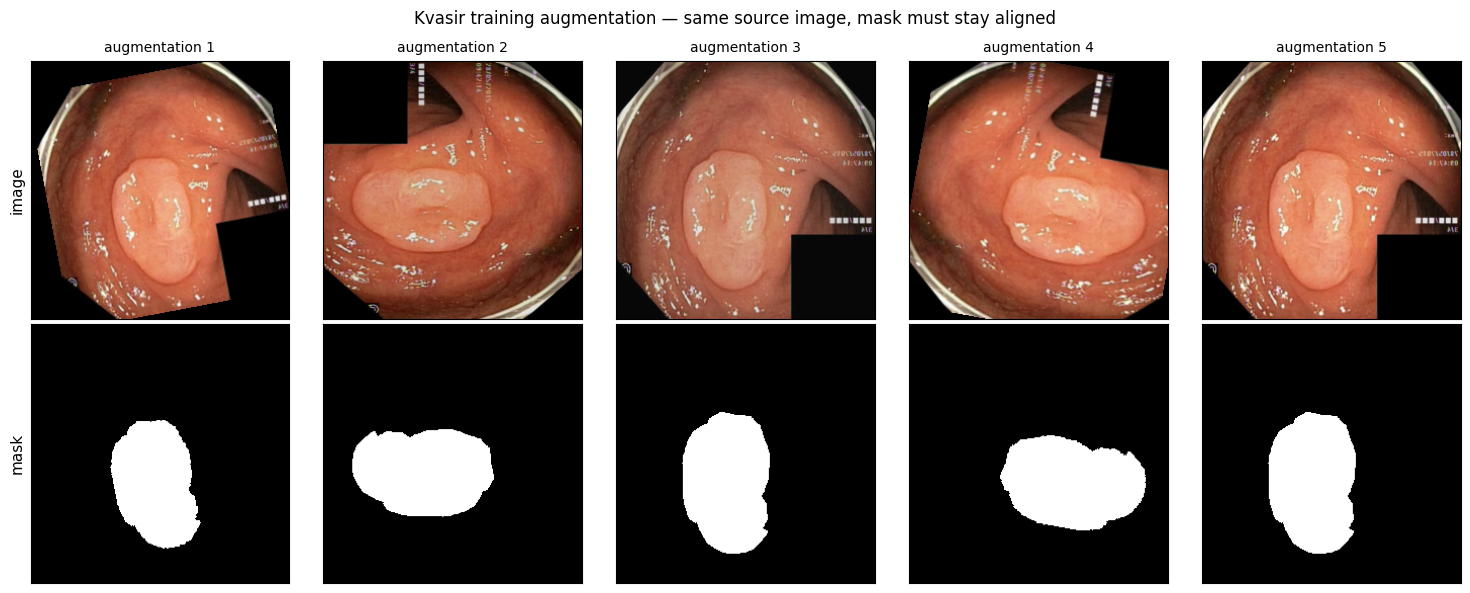

saved -> /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/figures/misc/augmentation_preview.png


In [ ]:
import matplotlib.pyplot as plt

SHOW_FIGURES = True    # display inline in Colab as well as writing to Drive

def denorm(x):
    '''Undo ImageNet normalization for display. x: (3,H,W) tensor -> (H,W,3) in [0,1].'''
    m = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    s = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x.detach().cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

def save_fig(fig, path, dpi=150):
    '''Saves to Drive, optionally shows inline, then frees the figure.'''
    os.makedirs(os.path.dirname(path), exist_ok=True)
    fig.savefig(path, dpi=dpi)
    if SHOW_FIGURES:
        try:
            from IPython.display import display
            display(fig)
        except Exception:
            pass
    plt.close(fig)
    print("saved ->", path)
    return path

set_seed(SEED)
_n = 5
fig, axes = plt.subplots(2, _n, figsize=(3 * _n, 6))
for j in range(_n):
    x, y = kv_train[0]
    axes[0, j].imshow(denorm(x)); axes[0, j].set_title(f"augmentation {j + 1}", fontsize=10)
    axes[1, j].imshow(y[0].numpy(), cmap="gray")
    for r in range(2):
        axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
axes[0, 0].set_ylabel("image", fontsize=11)
axes[1, 0].set_ylabel("mask", fontsize=11)
fig.suptitle("Kvasir training augmentation — same source image, mask must stay aligned")
fig.tight_layout()
save_fig(fig, os.path.join(DIRS["misc"], "augmentation_preview.png"))
set_seed(SEED)

## Section 13 — Trainer

Differences from the previous trainer:

- **Refuses to overwrite.** If the target checkpoint already exists it raises unless
  `ALLOW_OVERWRITE=True`. This is what prevents a crashed rerun from replacing good
  weights with epoch-1 weights.
- **Cosine LR annealing** from `LR` down to `LR/100`.
- **Early stopping** after `PATIENCE` epochs without a val-Dice improvement.
- **AMP** via `GradScaler`; the loss is computed in fp32 to keep Dice numerically stable.
- **Per-epoch history CSV flushed every epoch**, so a disconnect still leaves usable
  training curves.
- Checkpoints carry their full config, so any `.pth` can be traced back to its run.

In [ ]:
import os, time, csv, copy
import pandas as pd
from tqdm.auto import tqdm

def train_model(model, train_loader, val_loader, epochs, ckpt_path, history_csv,
                lr=LR, device=None, tag="model", patience=PATIENCE,
                use_amp=USE_AMP, allow_overwrite=ALLOW_OVERWRITE):
    device = device or DEVICE
    if os.path.exists(ckpt_path) and not allow_overwrite:
        raise FileExistsError(
            f"[{tag}] refusing to overwrite {ckpt_path}\n"
            f"Either change RUN_ID (recommended) or set ALLOW_OVERWRITE=True.")
    os.makedirs(os.path.dirname(ckpt_path), exist_ok=True)

    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]   # excludes the frozen teacher
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr * 0.01)
    crit = BCEDiceLoss()
    amp_on = use_amp and device == "cuda"
    scaler = torch.amp.GradScaler('cuda', enabled=amp_on)

    n_total = sum(p.numel() for p in model.parameters())
    n_train = sum(p.numel() for p in params)
    print(f"[{tag}] params total={n_total/1e6:.2f}M trainable={n_train/1e6:.2f}M "
          f"frozen={(n_total-n_train)/1e6:.2f}M | amp={amp_on}")

    best_dice, best_epoch, bad, history = -1.0, -1, 0, []
    t_start = time.time()

    for ep in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        run_loss, seen = 0.0, 0
        for x, y in tqdm(train_loader, desc=f"[{tag}] epoch {ep}/{epochs}", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=amp_on):
                out = model(x)
            loss = crit(out.float(), y)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            run_loss += loss.item() * x.size(0); seen += x.size(0)
        train_loss = run_loss / seen

        vmetrics, val_loss = evaluate_per_image(model, val_loader, device, use_amp, crit)
        vd, vi = float(vmetrics["dice"].mean()), float(vmetrics["iou"].mean())
        sched.step()

        row = dict(epoch=ep, train_loss=train_loss, val_loss=val_loss,
                   val_dice=vd, val_iou=vi, val_dice_std=float(vmetrics["dice"].std()),
                   lr=opt.param_groups[0]["lr"], epoch_seconds=round(time.time() - t0, 1))
        history.append(row)
        pd.DataFrame(history).to_csv(history_csv, index=False)   # flush every epoch

        msg = (f"[{tag}] ep {ep:3d}/{epochs}  train={train_loss:.4f}  val={val_loss:.4f}  "
               f"dice={vd:.4f}  iou={vi:.4f}  ({row['epoch_seconds']:.0f}s)")
        if vd > best_dice:
            best_dice, best_epoch, bad = vd, ep, 0
            torch.save({"model_state_dict": model.state_dict(), "epoch": ep,
                        "val_dice": vd, "val_iou": vi, "tag": tag,
                        "config": CONFIG}, ckpt_path)
            msg += "  <- best, saved"
        else:
            bad += 1
        print(msg)
        if bad >= patience:
            print(f"[{tag}] early stop at epoch {ep} (no val-Dice gain for {patience} epochs)")
            break

    mins = (time.time() - t_start) / 60
    print(f"[{tag}] DONE. best val_dice={best_dice:.4f} @ epoch {best_epoch} | {mins:.1f} min")
    return dict(tag=tag, best_val_dice=best_dice, best_epoch=best_epoch,
                epochs_run=len(history), minutes=round(mins, 1),
                params_total=n_total, params_trainable=n_train, ckpt=ckpt_path)

print("Trainer ready (overwrite-guarded, cosine LR, early stopping, AMP).")

Trainer ready (overwrite-guarded, cosine LR, early stopping, AMP).


## Section 14 — Load the Stage 1 teachers (read-only) and record their strength

The checkpoints carry their own COD10K validation Dice, which becomes the "teacher
strength" column of the paper. Note this is only **two** teachers, so it is a descriptive
comparison — two points cannot support a claim about a trend. `G1R` (random teacher) adds
the crucial third reference point: the same capacity with no camouflage knowledge.

In [ ]:
import pandas as pd

def load_teacher(kind, path, device=None):
    device = device or DEVICE
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Stage 1 teacher not found: {path}\n"
            f"Check that Drive is mounted and STAGE1_CKPT_DIR is correct.")
    t = UNet(3, 1, BASE_CHANNELS) if kind == "unet" else AttentionUNet(3, 1, BASE_CHANNELS)
    ck = torch.load(path, map_location=device)
    t.load_state_dict(ck["model_state_dict"], strict=True)
    t.eval()
    for p in t.parameters():
        p.requires_grad = False
    return t.to(device), ck

def make_random_teacher(kind="unet", seed=SEED + 1, device=None):
    '''Capacity control: identical architecture, frozen, but never trained on camouflage.'''
    device = device or DEVICE
    set_seed(seed)
    t = UNet(3, 1, BASE_CHANNELS) if kind == "unet" else AttentionUNet(3, 1, BASE_CHANNELS)
    t.eval()
    for p in t.parameters():
        p.requires_grad = False
    set_seed(SEED)
    return t.to(device)

TEACHER_SPECS = {"CU1": ("unet", CU1_CKPT), "CUA1": ("attention", CUA1_CKPT)}

rows = []
for name, (kind, path) in TEACHER_SPECS.items():
    t, ck = load_teacher(kind, path)
    x = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    with torch.no_grad():
        lo, ft = t(x, return_features=True)
    rows.append({"Teacher": name, "Architecture": "UNet" if kind == "unet" else "AttentionUNet",
                 "COD10K_val_dice": ck.get("val_dice"), "COD10K_val_iou": ck.get("val_iou"),
                 "best_epoch": ck.get("epoch"),
                 "params_M": round(sum(p.numel() for p in t.parameters()) / 1e6, 2)})
    print(f"{name}: logits {tuple(lo.shape)} | feats {[tuple(f.shape) for f in ft]}")
    del t, x, lo, ft
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

teacher_df = pd.DataFrame(rows)
teacher_df.to_csv(os.path.join(DIRS["tables"], "teacher_strength.csv"), index=False)
print("\n=== Stage 1 teacher strength (reused, NOT retrained) ===")
print(teacher_df.to_string(index=False))
print("\nBoth teachers load with strict=True and expose 5 feature maps "
      "(64/128/256/512/1024 channels).")

CU1: logits (2, 1, 256, 256) | feats [(2, 64, 256, 256), (2, 128, 128, 128), (2, 256, 64, 64), (2, 512, 32, 32), (2, 1024, 16, 16)]
CUA1: logits (2, 1, 256, 256) | feats [(2, 64, 256, 256), (2, 128, 128, 128), (2, 256, 64, 64), (2, 512, 32, 32), (2, 1024, 16, 16)]

=== Stage 1 teacher strength (reused, NOT retrained) ===
Teacher  Architecture  COD10K_val_dice  COD10K_val_iou  best_epoch  params_M
    CU1          UNet         0.467899        0.338799          14     31.04
   CUA1 AttentionUNet         0.466346        0.338737          20     31.39

Both teachers load with strict=True and expose 5 feature maps (64/128/256/512/1024 channels).


## Section 15 — Stage 2 model registry

| Key | Student | Width | Teacher | Params | Role |
|---|---|---|---|---|---|
| `M1` | UNet | 64 | — | 31.04M | unguided baseline |
| `MUA1` | AttentionUNet | 64 | — | 31.39M | unguided baseline |
| `G1` | UNet | 64 | CU1 | 64.87M | guided |
| `G2` | UNet | 64 | CUA1 | 64.87M | guided |
| `G3` | AttentionUNet | 64 | CU1 | 65.22M | guided |
| `G4` | AttentionUNet | 64 | CUA1 | 65.22M | guided |
| `G1R` | UNet | 64 | **random** | 64.87M | control: same capacity, no camouflage knowledge |
| `M1W` | UNet | **92** | — | 64.13M | control: parameter-matched, unguided |

The two controls exist because the progress brief flags a **capacity confound** — guided
models carry their frozen teacher at inference, so they have roughly 2x the parameters of
`M1`. Each control removes one explanation:

- `M1W` is a plain wider UNet with essentially the same parameter count as `G1`
  (64.13M vs 64.87M, 1.1% apart). If `M1W` alone closes the gap, the benefit is capacity.
- `G1R` has the identical guided architecture but a randomly initialized frozen teacher.
  If `G1R` matches `G1`/`G2`, the benefit is the fusion pathway, not camouflage knowledge.

Only compare **within** a student architecture: `M1` vs `G1`/`G2`/`G1R`/`M1W`, and `MUA1`
vs `G3`/`G4`. Comparing a UNet student against an Attention student confounds the guidance
effect with the architecture change.

In [ ]:
MODEL_SPECS = {
    "M1":   dict(family="baseline", student="unet",      teacher=None,     width=BASE_CHANNELS),
    "MUA1": dict(family="baseline", student="attention", teacher=None,     width=BASE_CHANNELS),
    "G1":   dict(family="guided",   student="unet",      teacher="CU1",    width=BASE_CHANNELS),
    "G2":   dict(family="guided",   student="unet",      teacher="CUA1",   width=BASE_CHANNELS),
    "G3":   dict(family="guided",   student="attention", teacher="CU1",    width=BASE_CHANNELS),
    "G4":   dict(family="guided",   student="attention", teacher="CUA1",   width=BASE_CHANNELS),
    "G1R":  dict(family="control",  student="unet",      teacher="RANDOM", width=BASE_CHANNELS),
    "M1W":  dict(family="control",  student="unet",      teacher=None,     width=WIDE_CHANNELS),
}

STAGE2_MODELS = ["M1", "MUA1", "G1", "G2", "G3", "G4"]
if INCLUDE_RANDOM_TEACHER:
    STAGE2_MODELS.append("G1R")
if INCLUDE_WIDE_BASELINE:
    STAGE2_MODELS.append("M1W")

# Which baseline each model must be compared against (same student architecture only).
BASELINE_OF = {"G1": "M1", "G2": "M1", "G1R": "M1", "M1W": "M1",
               "G3": "MUA1", "G4": "MUA1"}
ARCH_GROUPS = {
    "UNet students": ("M1", [k for k in ["G1", "G2", "G1R", "M1W"] if k in STAGE2_MODELS]),
    "Attention students": ("MUA1", [k for k in ["G3", "G4"] if k in STAGE2_MODELS]),
}

def build_model(key):
    spec = MODEL_SPECS[key]
    w = spec.get("width", BASE_CHANNELS)
    if spec["teacher"] is None:                     # baselines and the wide control
        return UNet(3, 1, w) if spec["student"] == "unet" else AttentionUNet(3, 1, w)
    if spec["teacher"] == "RANDOM":
        teacher = make_random_teacher("unet")
    else:
        kind, path = TEACHER_SPECS[spec["teacher"]]
        teacher, _ = load_teacher(kind, path)
    # Guided students stay at BASE_CHANNELS so the fusion channel counts line up
    # with the teacher's feature maps.
    return GuidedUNet(teacher, BASE_CHANNELS) if spec["student"] == "unet" \
        else GuidedAttentionUNet(teacher, BASE_CHANNELS)

def ckpt_path_of(key):
    return os.path.join(DIRS["ckpt"], key, f"{key.lower()}_best.pth")

def history_path_of(key):
    return os.path.join(DIRS["metrics"], f"history_{key}.csv")

print("Models to train:", STAGE2_MODELS)
for _k in STAGE2_MODELS:
    _m = build_model(_k)
    _t = sum(p.numel() for p in _m.parameters())
    _tr = sum(p.numel() for p in _m.parameters() if p.requires_grad)
    print(f"  {_k:5s} {MODEL_SPECS[_k]['family']:9s} width={MODEL_SPECS[_k]['width']:3d} "
          f"total={_t/1e6:6.2f}M trainable={_tr/1e6:6.2f}M")
    del _m

Models to train: ['M1', 'MUA1', 'G1', 'G2', 'G3', 'G4', 'G1R', 'M1W']
  M1    baseline  width= 64 total= 31.04M trainable= 31.04M
  MUA1  baseline  width= 64 total= 31.39M trainable= 31.39M
  G1    guided    width= 64 total= 64.87M trainable= 33.83M
  G2    guided    width= 64 total= 65.22M trainable= 33.83M
  G3    guided    width= 64 total= 65.22M trainable= 34.18M
  G4    guided    width= 64 total= 65.57M trainable= 34.18M
  G1R   control   width= 64 total= 64.87M trainable= 33.83M
  M1W   control   width= 92 total= 64.13M trainable= 64.13M


## Section 16 — STAGE 2 training

Roughly 25–50 minutes per model on a T4 with AMP, so expect about **4–6 hours** for all
eight. Each model is independent: if the session drops, re-run Sections 1–15 and leave
`SKIP_EXISTING = True` to resume from where you left off rather than starting over.

`M1W` is the heaviest model here (width 92, about 2x the activation memory of `M1`). It
should fit a T4 at batch 8 with AMP, but if you hit a CUDA out-of-memory error, set
`BATCH_SIZE = 4` in Section 3 and re-run Sections 3, 12 and 16 — then say so in the paper,
since `M1W` would no longer share the batch size of the other models.

In [ ]:
import json, gc

SKIP_EXISTING = True   # resume-friendly: skip models whose checkpoint already exists

summaries = []
for key in STAGE2_MODELS:
    ck = ckpt_path_of(key)
    if SKIP_EXISTING and os.path.exists(ck):
        print(f"[{key}] checkpoint exists -> skipping ({ck})")
        continue
    print("\n" + "=" * 78)
    print(f"TRAINING {key}  ({MODEL_SPECS[key]['family']}, student="
          f"{MODEL_SPECS[key]['student']}, teacher={MODEL_SPECS[key]['teacher']})")
    print("=" * 78)
    set_seed(SEED)                      # identical initialization/order for every model
    model = build_model(key)
    s = train_model(model, kv_tr_loader, kv_val_loader, STAGE2_EPOCHS,
                    ck, history_path_of(key), tag=key)
    s.update(MODEL_SPECS[key])
    summaries.append(s)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

if summaries:
    with open(os.path.join(DIRS["metrics"], "training_summary.json"), "w") as f:
        json.dump(summaries, f, indent=2)
    print("\n=== Training summary ===")
    print(pd.DataFrame(summaries)[["tag", "best_val_dice", "best_epoch",
                                   "epochs_run", "minutes"]].to_string(index=False))
else:
    print("Nothing trained (all checkpoints already present).")

[M1] checkpoint exists -> skipping (/content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/checkpoints/M1/m1_best.pth)
[MUA1] checkpoint exists -> skipping (/content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/checkpoints/MUA1/mua1_best.pth)

TRAINING G1  (guided, student=unet, teacher=CU1)
[G1] params total=64.87M trainable=33.83M frozen=31.04M | amp=True


[G1] epoch 1/30:   0%|          | 0/100 [00:00<?, ?it/s]

[G1] ep   1/30  train=1.1933  val=1.0768  dice=0.5188  iou=0.3766  (32s)  <- best, saved


[G1] epoch 2/30:   0%|          | 0/100 [00:00<?, ?it/s]

[G1] ep   2/30  train=1.0491  val=1.0056  dice=0.5278  iou=0.3937  (34s)  <- best, saved


...

[G1] ep  28/30  train=0.3584  val=0.3810  dice=0.8236  iou=0.7402  (37s)  <- best, saved


[G1] epoch 29/30:   0%|          | 0/100 [00:00<?, ?it/s]

[G1] ep  29/30  train=0.3579  val=0.3815  dice=0.8236  iou=0.7406  (37s)  <- best, saved


[G1] epoch 30/30:   0%|          | 0/100 [00:00<?, ?it/s]

[G1] ep  30/30  train=0.3563  val=0.3890  dice=0.8257  iou=0.7402  (37s)  <- best, saved
[G1] DONE. best val_dice=0.8257 @ epoch 30 | 18.5 min
[G2] checkpoint exists -> skipping (/content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/checkpoints/G2/g2_best.pth)
[G3] checkpoint exists -> skipping (/content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/checkpoints/G3/g3_best.pth)
[G4] checkpoint exists -> skipping (/content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/checkpoints/G4/g4_best.pth)
[G1R] checkpoint exists -> skipping (/content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/checkpoints/G1R/g1r_best.pth)
[M1W] checkpoint exists -> skipping (/content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/checkpoints/M1W/m1w_best.pth)

=== Training summary ===
tag  best_val_dice  best_epoch  epochs_run  minutes
 G1       0.825737          30          30     18.5


## Section 17 — Training curves

Two figures: validation Dice per epoch (does anything still improve at 30 epochs?) and
train-versus-validation loss (is anything overfitting the way Stage 1 did?). If a curve
is still climbing at epoch 30, that is your evidence for a longer budget; if it plateaus,
that is your justification for stopping at 30.

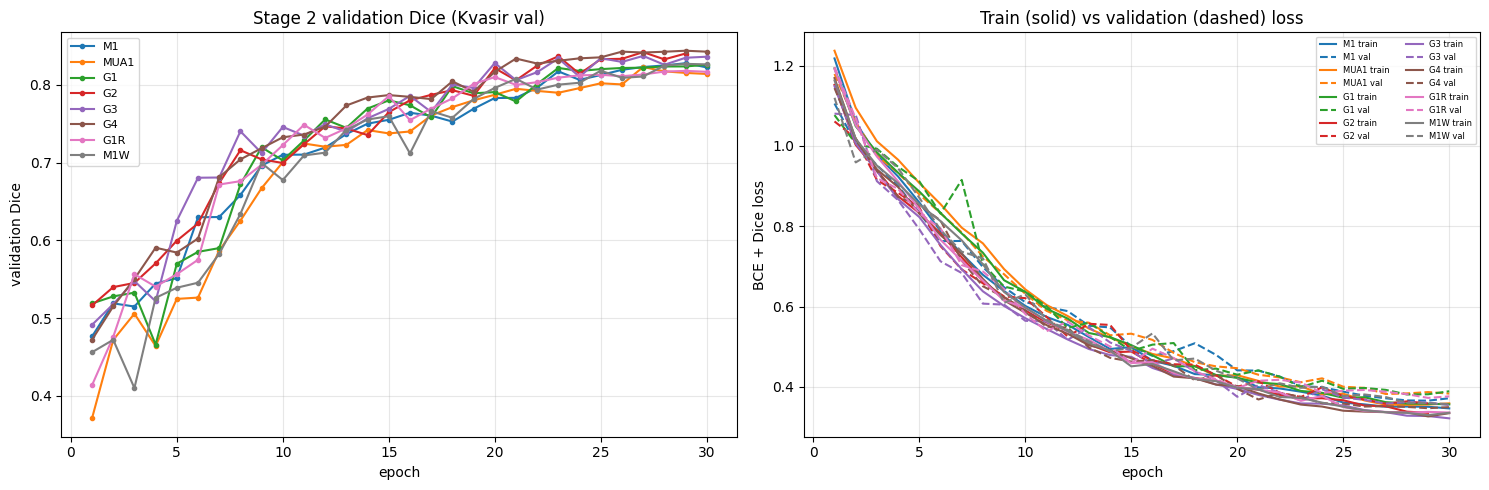

saved -> /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/figures/curves/training_curves.png

Best epoch per model (is 30 epochs enough?):
  M1    best val_dice=0.8278 @ epoch 29 of 30
  MUA1  best val_dice=0.8229 @ epoch 27 of 30
  G1    best val_dice=0.8257 @ epoch 30 of 30
  G2    best val_dice=0.8420 @ epoch 27 of 29
  G3    best val_dice=0.8371 @ epoch 27 of 30
  G4    best val_dice=0.8439 @ epoch 29 of 30
  G1R   best val_dice=0.8179 @ epoch 29 of 30
  M1W   best val_dice=0.8269 @ epoch 29 of 30


In [ ]:
import matplotlib.pyplot as plt

hists = {}
for key in STAGE2_MODELS:
    p = history_path_of(key)
    if os.path.exists(p):
        hists[key] = pd.read_csv(p)

if hists:
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    for key, h in hists.items():
        ax[0].plot(h.epoch, h.val_dice, marker="o", ms=3, label=key)
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("validation Dice")
    ax[0].set_title("Stage 2 validation Dice (Kvasir val)")
    ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

    for key, h in hists.items():
        l, = ax[1].plot(h.epoch, h.train_loss, label=f"{key} train")
        ax[1].plot(h.epoch, h.val_loss, "--", color=l.get_color(), label=f"{key} val")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("BCE + Dice loss")
    ax[1].set_title("Train (solid) vs validation (dashed) loss")
    ax[1].legend(fontsize=6, ncol=2); ax[1].grid(alpha=.3)

    fig.tight_layout()
    save_fig(fig, os.path.join(DIRS["curves"], "training_curves.png"))

    print("\nBest epoch per model (is 30 epochs enough?):")
    for key, h in hists.items():
        b = int(h.val_dice.idxmax())
        print(f"  {key:5s} best val_dice={h.val_dice.max():.4f} @ epoch {int(h.epoch[b])}"
              f" of {int(h.epoch.max())}")
else:
    print("No history CSVs found — run Section 16 first.")

In [ ]:
import torch
torch.serialization.add_safe_globals([torch.torch_version.TorchVersion])

## Section 18 — Quantitative results: Kvasir test + ISIC

Every model is evaluated on the held-out Kvasir **test** split (never used for checkpoint
selection) and on ISIC (never used at all). Metrics are per-image, so each cell is
`mean ± std` over images. The full per-image values are written to CSV, which is what the
significance tests in Section 19 consume.

ISIC must be reported as **zero-shot transfer**: models are trained on Kvasir polyps and
evaluated on skin lesions with no fine-tuning. That framing is what makes an absolute Dice
of 0.15–0.35 a meaningful number rather than a broken one, and the brief lists it as a
required caveat.

In [ ]:
import torch
torch.serialization.add_safe_globals([torch.torch_version.TorchVersion])

In [ ]:
import numpy as np, pandas as pd, torch, gc

EVAL_SETS = {"kvasir_test": kv_test_loader, "isic": isic_loader}

per_image = {}    # per_image[(dataset, model)] = dict of numpy arrays
rows = []

for key in STAGE2_MODELS:
    ck = ckpt_path_of(key)
    if not os.path.exists(ck):
        print("SKIP (missing checkpoint):", ck)
        continue
    model = build_model(key).to(DEVICE)
    state = torch.load(ck, map_location=DEVICE)
    model.load_state_dict(state["model_state_dict"], strict=True)

    row = {"Model": key, "Family": MODEL_SPECS[key]["family"],
           "Student": MODEL_SPECS[key]["student"], "Teacher": MODEL_SPECS[key]["teacher"],
           "best_epoch": state.get("epoch")}
    for ds_name, loader in EVAL_SETS.items():
        m, loss = evaluate_per_image(model, loader, DEVICE, USE_AMP)
        per_image[(ds_name, key)] = m
        row.update(summarize(m, prefix=ds_name + "_"))
        row[ds_name + "_loss"] = loss
        print(f"{key:5s} {ds_name:12s} dice={m['dice'].mean():.4f}+-{m['dice'].std():.4f} "
              f"iou={m['iou'].mean():.4f}")
    rows.append(row)
    del model, state
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(rows).set_index("Model")
results_df.to_csv(os.path.join(DIRS["tables"], "results_full.csv"))

# Flat per-image table (one row per image per model per dataset) for reanalysis.
recs = []
for (ds_name, key), m in per_image.items():
    ids = (kv_test if ds_name == "kvasir_test" else isic_ds)
    for i in range(len(m["dice"])):
        r = {"dataset": ds_name, "model": key, "index": i, "sample_id": ids.sample_id(i)}
        r.update({k: float(m[k][i]) for k in METRIC_NAMES})
        recs.append(r)
per_image_df = pd.DataFrame(recs)
per_image_df.to_csv(os.path.join(DIRS["metrics"], "per_image_metrics.csv"), index=False)

def headline(ds):
    out = pd.DataFrame({
        "Dice": [f"{results_df.loc[k, ds+'_dice_mean']:.4f} +- {results_df.loc[k, ds+'_dice_std']:.4f}"
                 for k in results_df.index],
        "IoU":  [f"{results_df.loc[k, ds+'_iou_mean']:.4f} +- {results_df.loc[k, ds+'_iou_std']:.4f}"
                 for k in results_df.index],
        "Precision": [f"{results_df.loc[k, ds+'_precision_mean']:.4f}" for k in results_df.index],
        "Recall":    [f"{results_df.loc[k, ds+'_recall_mean']:.4f}" for k in results_df.index],
    }, index=results_df.index)
    return out

for ds in EVAL_SETS:
    t = headline(ds)
    t.to_csv(os.path.join(DIRS["tables"], f"headline_{ds}.csv"))
    label = "in-domain, held-out test split" if ds == "kvasir_test" \
        else "ZERO-SHOT transfer, no fine-tuning"
    print(f"\n=== {ds} ({label}) — mean +- std over images ===")
    print(t.to_string())

print("\nsaved ->", os.path.join(DIRS["tables"], "results_full.csv"))
print("saved ->", os.path.join(DIRS["metrics"], "per_image_metrics.csv"))

M1    kvasir_test  dice=0.7930+-0.2200 iou=0.7002
M1    isic         dice=0.2005+-0.2528 iou=0.1389
MUA1  kvasir_test  dice=0.7906+-0.2122 iou=0.6947
MUA1  isic         dice=0.2379+-0.2583 iou=0.1632
G1    kvasir_test  dice=0.7981+-0.2079 iou=0.7035
G1    isic         dice=0.1861+-0.2496 iou=0.1286
G2    kvasir_test  dice=0.8019+-0.2265 iou=0.7150
G2    isic         dice=0.1791+-0.2451 iou=0.1235
G3    kvasir_test  dice=0.7983+-0.2177 iou=0.7070
G3    isic         dice=0.2495+-0.2946 iou=0.1823
G4    kvasir_test  dice=0.8085+-0.2097 iou=0.7195
G4    isic         dice=0.0839+-0.1768 iou=0.0556
G1R   kvasir_test  dice=0.7995+-0.2051 iou=0.7055
G1R   isic         dice=0.0923+-0.1936 iou=0.0635
M1W   kvasir_test  dice=0.7920+-0.2128 iou=0.6975
M1W   isic         dice=0.1434+-0.2361 iou=0.1004

=== kvasir_test (in-domain, held-out test split) — mean +- std over images ===
                   Dice               IoU Precision  Recall
Model                                                      


## Section 19 — Hypothesis test: does camouflage guidance actually help?

For every guided model we take the **paired** per-image Dice against its own baseline
(same image, same split, same order) and run a Wilcoxon signed-rank test. Pairing is what
makes this powerful with a single seed: it removes image difficulty as a source of
variance, so a consistent small gain becomes detectable.

Two honesty notes that belong in the paper. First, this tests variability *across images*,
not across training seeds — it cannot tell you the result would survive a different
initialization. Second, we run several comparisons, so a p-value near 0.05 should be
treated with the Holm-corrected column, not the raw one.

`G1R` is the interpretive key. If `G1`/`G2` beat `M1` but `G1R` does too by a similar
margin, the gain is extra capacity, not camouflage knowledge.

In [ ]:
from scipy.stats import wilcoxon
import numpy as np, pandas as pd

def holm(pvals):
    order = np.argsort(pvals)
    n = len(pvals)
    adj = np.empty(n); run = 0.0
    for rank, i in enumerate(order):
        val = (n - rank) * pvals[i]
        run = max(run, val)
        adj[i] = min(1.0, run)
    return adj

test_rows = []
for ds in EVAL_SETS:
    for model, base in BASELINE_OF.items():
        if (ds, model) not in per_image or (ds, base) not in per_image:
            continue
        a = per_image[(ds, model)]["dice"]
        b = per_image[(ds, base)]["dice"]
        diff = a - b
        if np.allclose(diff, 0):
            stat, p = np.nan, 1.0
        else:
            stat, p = wilcoxon(a, b, zero_method="wilcox", alternative="two-sided")
        test_rows.append({
            "dataset": ds, "model": model, "baseline": base,
            "dice_model": a.mean(), "dice_baseline": b.mean(),
            "delta_mean": diff.mean(), "delta_median": np.median(diff),
            "won_pct": 100.0 * (diff > 0).mean(),
            "p_value": p, "n": len(diff),
        })

tests_df = pd.DataFrame(test_rows)
if not tests_df.empty:
    tests_df["p_holm"] = np.concatenate([
        holm(g["p_value"].values) for _, g in tests_df.groupby("dataset", sort=False)])
    tests_df["verdict"] = np.where(
        (tests_df.p_holm < 0.05) & (tests_df.delta_mean > 0), "HELPS (sig.)",
        np.where((tests_df.p_holm < 0.05) & (tests_df.delta_mean < 0), "HURTS (sig.)",
                 "no significant difference"))
    tests_df.to_csv(os.path.join(DIRS["tables"], "significance_tests.csv"), index=False)

    for ds, g in tests_df.groupby("dataset", sort=False):
        print(f"\n=== {ds}: paired Wilcoxon, guided vs its own baseline ===")
        print(g[["model", "baseline", "dice_baseline", "dice_model", "delta_mean",
                 "won_pct", "p_value", "p_holm", "verdict"]].to_string(index=False,
                 float_format=lambda v: f"{v:.4f}"))

    print("\n" + "=" * 78)
    print("CONTROL READ-OUT — is the gain camouflage knowledge, or just capacity?")
    print("=" * 78)
    for ds in EVAL_SETS:
        sub = tests_df[tests_df.dataset == ds].set_index("model")
        camo = {m: sub.loc[m, "delta_mean"] for m in ["G1", "G2"] if m in sub.index}
        if not camo:
            continue
        best_camo = max(camo.values())
        print(f"\n{ds}  (all deltas are Dice vs the M1 baseline)")
        for m, v in camo.items():
            print(f"  {m:4s} camouflage teacher     : {v:+.4f}")
        wide = sub.loc["M1W", "delta_mean"] if "M1W" in sub.index else None
        rand = sub.loc["G1R", "delta_mean"] if "G1R" in sub.index else None
        if wide is not None:
            print(f"  M1W  parameter-matched UNet : {wide:+.4f}")
        if rand is not None:
            print(f"  G1R  random frozen teacher  : {rand:+.4f}")

        beats_wide = wide is None or best_camo > wide
        beats_rand = rand is None or best_camo > rand
        if beats_wide and beats_rand:
            print("  VERDICT: camouflage guidance beats BOTH controls -> the gain is "
                  "attributable to camouflage pre-training.")
        elif not beats_wide and not beats_rand:
            print("  VERDICT: both controls match or beat the camouflage teachers -> the "
                  "gain is capacity, NOT camouflage knowledge. Do not claim otherwise.")
        elif not beats_wide:
            print("  VERDICT: a plain wider UNet matches the guided models -> report the "
                  "gain as a capacity effect.")
        else:
            print("  VERDICT: a random frozen teacher matches the camouflage teachers -> "
                  "the fusion pathway helps, but camouflage pre-training specifically "
                  "does not.")
else:
    print("No tests computed — run Section 18 first.")


=== kvasir_test: paired Wilcoxon, guided vs its own baseline ===
model baseline  dice_baseline  dice_model  delta_mean  won_pct  p_value  p_holm                   verdict
   G1       M1         0.7930      0.7981      0.0051  49.0000   0.8608  1.0000 no significant difference
   G2       M1         0.7930      0.8019      0.0088  58.0000   0.1347  0.6737 no significant difference
  G1R       M1         0.7930      0.7995      0.0064  55.0000   0.1607  0.6737 no significant difference
  M1W       M1         0.7930      0.7920     -0.0010  52.0000   0.7833  1.0000 no significant difference
   G3     MUA1         0.7906      0.7983      0.0077  55.0000   0.4660  1.0000 no significant difference
   G4     MUA1         0.7906      0.8085      0.0179  56.0000   0.1010  0.6059 no significant difference

=== isic: paired Wilcoxon, guided vs its own baseline ===
model baseline  dice_baseline  dice_model  delta_mean  won_pct  p_value  p_holm                   verdict
   G1       M1         0.20

### Section 19b — Per-image Dice distributions

The progress brief asks for per-image Dice distributions rather than means alone, and this
is the figure that delivers it. A mean of 0.34 built from "excellent on a third of images,
zero on the rest" is a completely different result from a uniform 0.34, and only the
distribution shows which one you have. Box shows the median and quartiles, the triangle is
the mean, and every image is plotted as a faint dot.

Watch for a cluster pinned at Dice = 0 on ISIC. Those are total misses, and if guidance
mainly works by converting total misses into partial hits, that is a more interesting and
more defensible claim than a shift in the average.

/tmp/ipykernel_508/3250273471.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=models, showmeans=True, patch_artist=True,


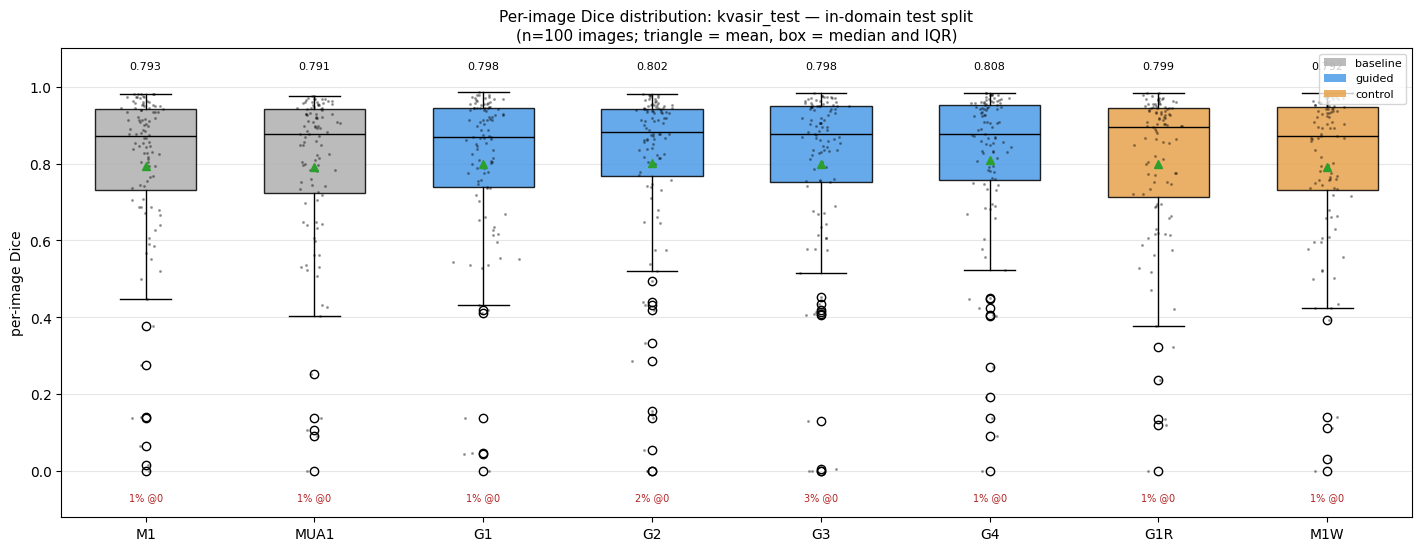

saved -> /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/figures/distributions/dice_distribution_kvasir_test.png

kvasir_test: median / IQR / share of images at Dice<0.01
  M1    median=0.8715  IQR=[0.7302, 0.9430]  zeros=  1.0%
  MUA1  median=0.8773  IQR=[0.7247, 0.9424]  zeros=  1.0%
  G1    median=0.8680  IQR=[0.7380, 0.9449]  zeros=  1.0%
  G2    median=0.8826  IQR=[0.7667, 0.9428]  zeros=  2.0%
  G3    median=0.8762  IQR=[0.7534, 0.9487]  zeros=  3.0%
  G4    median=0.8760  IQR=[0.7567, 0.9526]  zeros=  1.0%
  G1R   median=0.8957  IQR=[0.7143, 0.9436]  zeros=  1.0%
  M1W   median=0.8718  IQR=[0.7311, 0.9479]  zeros=  1.0%


/tmp/ipykernel_508/3250273471.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=models, showmeans=True, patch_artist=True,


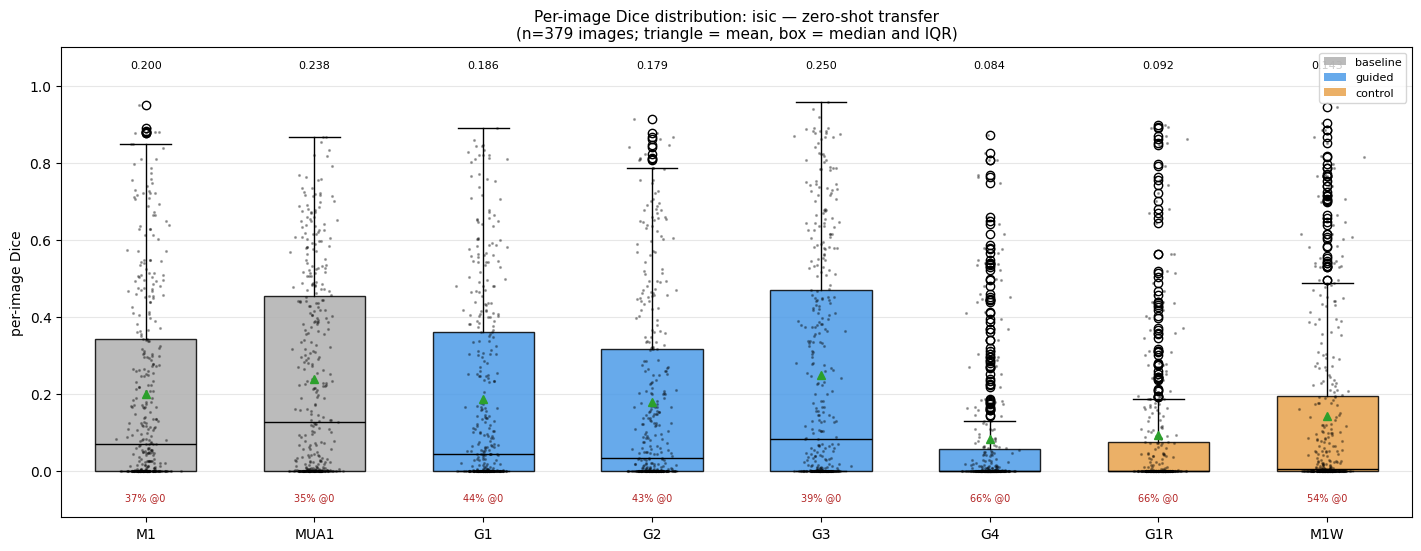

saved -> /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/figures/distributions/dice_distribution_isic.png

isic: median / IQR / share of images at Dice<0.01
  M1    median=0.0705  IQR=[0.0000, 0.3425]  zeros= 37.2%
  MUA1  median=0.1259  IQR=[0.0000, 0.4538]  zeros= 35.4%
  G1    median=0.0432  IQR=[0.0000, 0.3612]  zeros= 44.3%
  G2    median=0.0348  IQR=[0.0000, 0.3158]  zeros= 43.3%
  G3    median=0.0835  IQR=[0.0000, 0.4693]  zeros= 39.1%
  G4    median=0.0000  IQR=[0.0000, 0.0572]  zeros= 65.7%
  G1R   median=0.0000  IQR=[0.0000, 0.0759]  zeros= 66.2%
  M1W   median=0.0041  IQR=[0.0000, 0.1959]  zeros= 53.6%


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

FAMILY_COLOR = {"baseline": "#b0b0b0", "guided": "#4c9be8", "control": "#e8a34c"}

for ds in EVAL_SETS:
    models = [k for k in STAGE2_MODELS if (ds, k) in per_image]
    if not models:
        continue
    data = [per_image[(ds, k)]["dice"] for k in models]
    fig, ax = plt.subplots(figsize=(max(7.0, 1.45 * len(models) + 2.5), 5.4),
                           constrained_layout=True)
    bp = ax.boxplot(data, labels=models, showmeans=True, patch_artist=True,
                    medianprops=dict(color="black"), widths=0.6)
    for patch, k in zip(bp["boxes"], models):
        patch.set_facecolor(FAMILY_COLOR[MODEL_SPECS[k]["family"]])
        patch.set_alpha(0.85)
    jitter = np.random.RandomState(SEED)
    for i, d in enumerate(data, start=1):
        ax.plot(jitter.normal(i, 0.055, len(d)), d, ".", ms=2.5, alpha=0.28, color="black")
    for i, d in enumerate(data, start=1):
        ax.annotate(f"{d.mean():.3f}", (i, 1.045), ha="center", fontsize=8)
        zero_pct = 100.0 * (d < 0.01).mean()
        if zero_pct > 0:
            ax.annotate(f"{zero_pct:.0f}% @0", (i, -0.075), ha="center", fontsize=7,
                        color="firebrick")
    ax.set_ylim(-0.12, 1.10)
    ax.set_ylabel("per-image Dice")
    zs = " — zero-shot transfer" if ds != "kvasir_test" else " — in-domain test split"
    ax.set_title(f"Per-image Dice distribution: {ds}{zs}\n(n={len(data[0])} images; "
                 f"triangle = mean, box = median and IQR)", fontsize=11)
    ax.grid(alpha=0.3, axis="y")
    handles = [plt.Rectangle((0, 0), 1, 1, fc=c, alpha=0.85) for c in FAMILY_COLOR.values()]
    ax.legend(handles, FAMILY_COLOR.keys(), fontsize=8, loc="upper right")
    save_fig(fig, os.path.join(DIRS["dist"], f"dice_distribution_{ds}.png"))

    print(f"\n{ds}: median / IQR / share of images at Dice<0.01")
    for k, d in zip(models, data):
        q1, q3 = np.percentile(d, [25, 75])
        print(f"  {k:5s} median={np.median(d):.4f}  IQR=[{q1:.4f}, {q3:.4f}]  "
              f"zeros={100.0*(d<0.01).mean():5.1f}%")

## Section 20 — Qualitative results (the figures the paper needs)

Three panels per dataset, all with **fixed, deterministic** sample selection so nothing
looks cherry-picked:

1. `fixed` — the first samples in split order.
2. `worst_baseline` — where the unguided baseline scores lowest, i.e. the hard cases.
3. `best_gain` — where guidance helps most.

Each panel is `Image | Ground Truth | M1 | MUA1 | G1 | G2 | G3 | G4 | G1R`, with each
prediction's own Dice in its title. Individual PNGs are also written per model per sample
so you can compose custom figures in LaTeX. Include a `worst_baseline` panel in the
paper — reviewers specifically look for failure cases.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np, torch, gc

N_SHOW = 4          # samples per panel
PRED_ALPHA = 0.45   # overlay strength

@torch.no_grad()
def predict_indices(key, dataset, indices):
    '''Returns {index: (prob_map HxW, dice)} for one model on selected dataset indices.'''
    ck = ckpt_path_of(key)
    model = build_model(key).to(DEVICE)
    model.load_state_dict(torch.load(ck, map_location=DEVICE)["model_state_dict"], strict=True)
    model.eval()
    out = {}
    for i in indices:
        x, y = dataset[i]
        xb = x.unsqueeze(0).to(DEVICE)
        logits = model(xb).float()
        prob = torch.sigmoid(logits)[0, 0].cpu().numpy()
        d = float(per_image_metrics(logits, y.unsqueeze(0).to(DEVICE))["dice"][0])
        out[i] = (prob, d)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return out

def pick_indices(ds_name, n=N_SHOW):
    '''Deterministic sample selection for the three panel types.'''
    base = "M1"
    sel = {"fixed": list(range(n))}
    if (ds_name, base) in per_image:
        bd = per_image[(ds_name, base)]["dice"]
        sel["worst_baseline"] = list(np.argsort(bd)[:n])
        guided = [k for k in ["G1", "G2", "G3", "G4"] if (ds_name, k) in per_image]
        if guided:
            best = np.max([per_image[(ds_name, k)]["dice"] for k in guided], axis=0)
            sel["best_gain"] = list(np.argsort(-(best - bd))[:n])
    return sel

def overlay(img, mask, color):
    o = img.copy()
    m = mask > 0.5
    for c in range(3):
        o[..., c] = np.where(m, (1 - PRED_ALPHA) * o[..., c] + PRED_ALPHA * color[c], o[..., c])
    return o

def draw_panel(ds_name, dataset, indices, panel_name, models, preds):
    ncols = 2 + len(models)
    # constrained_layout (not tight_layout) so per-axis xlabels cannot be clipped
    # by the row below them.
    fig, axes = plt.subplots(len(indices), ncols,
                             figsize=(2.5 * ncols, 2.85 * len(indices)),
                             squeeze=False, constrained_layout=True)
    for r, i in enumerate(indices):
        x, y = dataset[i]
        img = denorm(x); gt = y[0].numpy()
        axes[r][0].imshow(img)
        axes[r][0].set_ylabel(dataset.sample_id(i), fontsize=7)
        if r == 0:
            axes[r][0].set_title("Image", fontsize=10)
        axes[r][1].imshow(overlay(img, gt, (0.0, 1.0, 0.0)))
        if r == 0:
            axes[r][1].set_title("Ground Truth", fontsize=10)
        for c, k in enumerate(models):
            prob, d = preds[k][i]
            axes[r][2 + c].imshow(overlay(img, prob > 0.5, (1.0, 0.0, 0.0)))
            if r == 0:
                axes[r][2 + c].set_title(k, fontsize=11)
            # Dice goes below the panel; as a title it collides with the row above.
            axes[r][2 + c].set_xlabel(f"Dice={d:.3f}", fontsize=9)
        for c in range(ncols):
            axes[r][c].set_xticks([]); axes[r][c].set_yticks([])

    fig.suptitle(f"{ds_name} — {panel_name} (green = ground truth, red = prediction)",
                 fontsize=13)
    out_dir = os.path.join(DIRS["qual"], ds_name)
    os.makedirs(out_dir, exist_ok=True)
    save_fig(fig, os.path.join(out_dir, f"panel_{panel_name}.png"), dpi=180)

    # Individual PNGs for LaTeX composition.
    for r, i in enumerate(indices):
        x, y = dataset[i]
        stem = os.path.join(out_dir, f"{panel_name}_{dataset.sample_id(i)}")
        plt.imsave(stem + "_image.png", denorm(x))
        plt.imsave(stem + "_gt.png", y[0].numpy(), cmap="gray")
        for k in models:
            plt.imsave(stem + f"_{k}.png", (preds[k][i][0] > 0.5).astype(float), cmap="gray")

avail = [k for k in STAGE2_MODELS if os.path.exists(ckpt_path_of(k))]

for ds_name, dataset in [("kvasir_test", kv_test), ("isic", isic_ds)]:
    panels = pick_indices(ds_name)
    # Predict once per model over every index any panel needs, so each checkpoint is
    # loaded from Drive a single time instead of once per panel.
    union = sorted({int(i) for idxs in panels.values() for i in idxs})
    print(f"\n[{ds_name}] {len(avail)} models x {len(union)} samples")
    preds = {k: predict_indices(k, dataset, union) for k in avail}
    for panel_name, idxs in panels.items():
        draw_panel(ds_name, dataset, [int(i) for i in idxs], panel_name, avail, preds)

print("\nQualitative figures written to", DIRS["qual"])

Output hidden; open in https://colab.research.google.com to view.

## Section 21 — Feature visualization: what does the teacher actually contribute?

For each guided model and a couple of fixed images, every encoder level is shown as four
maps: the frozen **teacher** feature, the **student** feature, the **fused** result, and
`|fused − student|`.

That last column is the one worth putting in the paper. Teacher and student maps are
suggestive but hard to argue from; the difference map directly answers "what did guidance
change?" If it concentrates on the lesion boundary, that is your mechanism. If it is
diffuse noise, the guidance is not doing what the story claims — which is worth knowing
before a reviewer finds out.

Maps are channel-mean summaries, min-max normalized per panel and upsampled to the input
resolution. State that in the caption; it is a summary, not the raw tensor.

In [ ]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
import numpy as np, gc

FEAT_MODELS  = [k for k in ["G1", "G2", "G3", "G4", "G1R"] if os.path.exists(ckpt_path_of(k))]
FEAT_SAMPLES = 2

def _to_map(t):
    '''(1,C,h,w) -> (H,W) in [0,1]: channel mean, upsampled, min-max normalized.'''
    m = t.float().mean(1, keepdim=True)
    m = F.interpolate(m, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)
    m = m[0, 0].detach().cpu().numpy()
    lo, hi = np.percentile(m, 1), np.percentile(m, 99)
    return np.clip((m - lo) / (hi - lo + 1e-8), 0, 1)

@torch.no_grad()
def feature_figure(model, key, dataset, idx, ds_name):
    x, y = dataset[idx]
    xb = x.unsqueeze(0).to(DEVICE)
    logits, t_feats, s_feats, f_feats = model(xb, return_all=True)
    pred = (torch.sigmoid(logits.float())[0, 0].cpu().numpy() > 0.5)

    cols = ["teacher", "student", "fused", "|fused - student|"]
    fig, axes = plt.subplots(len(FEATURE_LEVELS), 4,
                             figsize=(3.1 * 4, 2.9 * len(FEATURE_LEVELS)),
                             squeeze=False, constrained_layout=True)
    for r, level in enumerate(FEATURE_LEVELS):
        maps = [_to_map(t_feats[r]), _to_map(s_feats[r]), _to_map(f_feats[r]),
                _to_map((f_feats[r] - s_feats[r]).abs())]
        for c in range(4):
            axes[r][c].imshow(maps[c], cmap="inferno")
            axes[r][c].set_xticks([]); axes[r][c].set_yticks([])
            if r == 0:
                axes[r][c].set_title(cols[c], fontsize=11)
        axes[r][0].set_ylabel(level, fontsize=11)
    fig.suptitle(f"{key} on {ds_name}/{dataset.sample_id(idx)} — channel-mean feature maps",
                 fontsize=13)
    out_dir = os.path.join(DIRS["feat"], ds_name)
    os.makedirs(out_dir, exist_ok=True)
    stem = f"{key}_{dataset.sample_id(idx)}"
    save_fig(fig, os.path.join(out_dir, f"features_{stem}.png"), dpi=170)

    # Companion panel so the feature maps have visual context.
    fig2, ax2 = plt.subplots(1, 3, figsize=(9, 3.2))
    ax2[0].imshow(denorm(x));                 ax2[0].set_title("input")
    ax2[1].imshow(y[0].numpy(), cmap="gray"); ax2[1].set_title("ground truth")
    ax2[2].imshow(pred, cmap="gray");         ax2[2].set_title(f"{key} prediction")
    for a in ax2:
        a.set_xticks([]); a.set_yticks([])
    fig2.tight_layout()
    save_fig(fig2, os.path.join(out_dir, f"context_{stem}.png"), dpi=170)

# One checkpoint load per model, reused across every dataset and sample.
for key in FEAT_MODELS:
    model = build_model(key).to(DEVICE)
    model.load_state_dict(torch.load(ckpt_path_of(key), map_location=DEVICE)["model_state_dict"],
                          strict=True)
    model.eval()
    for ds_name, dataset in [("kvasir_test", kv_test), ("isic", isic_ds)]:
        for idx in range(min(FEAT_SAMPLES, len(dataset))):
            feature_figure(model, key, dataset, idx, ds_name)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nFeature figures written to", DIRS["feat"])

Output hidden; open in https://colab.research.google.com to view.

## Section 22 — Efficiency: parameters, GMACs/GFLOPs, latency, FPS

This table is a defense, not decoration. A guided model keeps its frozen teacher at
inference, so it carries roughly **2x the parameters and compute** of its baseline. State
that plainly and pair it with the `G1R` control from Section 19, otherwise the obvious
reviewer question — "did you just double the capacity?" — has no answer.

Latency is measured after warm-up with explicit CUDA synchronization, reported as
mean ± std over repeats. Colab GPUs are shared, so run this when the session is otherwise
idle and report the hardware in the paper.

In [ ]:
import time, copy, numpy as np, pandas as pd, torch, gc

WARMUP, REPEATS = 10, 40

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, train

def measure_macs(model):
    try:
        from thop import profile
        m = copy.deepcopy(model).eval().to(DEVICE)
        x = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
        macs, _ = profile(m, inputs=(x,), verbose=False)
        del m, x
        return float(macs)
    except Exception as e:
        print("  thop failed:", e)
        return float("nan")

@torch.no_grad()
def measure_latency(model, batch_size):
    model.eval().to(DEVICE)
    x = torch.randn(batch_size, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    for _ in range(WARMUP):
        model(x)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    ts = []
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        model(x)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        ts.append((time.perf_counter() - t0) * 1000.0)
    del x
    return float(np.mean(ts)), float(np.std(ts))

rows = []
for key in STAGE2_MODELS:
    if not os.path.exists(ckpt_path_of(key)):
        continue
    model = build_model(key).to(DEVICE).eval()
    total, train = count_params(model)
    macs = measure_macs(model)
    l1, s1 = measure_latency(model, 1)
    l8, s8 = measure_latency(model, BATCH_SIZE)
    rows.append({
        "Model": key, "Family": MODEL_SPECS[key]["family"],
        "Params_M": round(total / 1e6, 2),
        "Trainable_M": round(train / 1e6, 2),
        "Frozen_M": round((total - train) / 1e6, 2),
        "GMACs": round(macs / 1e9, 2), "GFLOPs": round(2 * macs / 1e9, 2),
        "Latency_bs1_ms": round(l1, 2), "Latency_bs1_std": round(s1, 2),
        "FPS_bs1": round(1000.0 / l1, 1),
        f"Latency_bs{BATCH_SIZE}_ms": round(l8, 2),
        f"FPS_bs{BATCH_SIZE}": round(BATCH_SIZE * 1000.0 / l8, 1),
    })
    print(f"{key:5s} params={total/1e6:6.2f}M  GMACs={macs/1e9:7.2f}  "
          f"bs1={l1:6.2f}ms ({1000.0/l1:5.1f} FPS)")
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

eff_df = pd.DataFrame(rows).set_index("Model")
eff_df.to_csv(os.path.join(DIRS["tables"], "efficiency.csv"))
print("\n=== Efficiency (image %dx%d, %s) ===" % (IMAGE_SIZE, IMAGE_SIZE, CONFIG["gpu"]))
print(eff_df.to_string())

for base in ["M1", "MUA1"]:
    if base in eff_df.index:
        for k in eff_df.index:
            if BASELINE_OF.get(k) == base:
                print(f"{k} vs {base}: {eff_df.loc[k,'Params_M']/eff_df.loc[base,'Params_M']:.2f}x params, "
                      f"{eff_df.loc[k,'GMACs']/eff_df.loc[base,'GMACs']:.2f}x MACs, "
                      f"{eff_df.loc[base,'FPS_bs1']/eff_df.loc[k,'FPS_bs1']:.2f}x slower")

M1    params= 31.04M  GMACs=  54.74  bs1= 40.47ms ( 24.7 FPS)
MUA1  params= 31.39M  GMACs=  55.82  bs1= 41.09ms ( 24.3 FPS)
G1    params= 64.87M  GMACs= 112.16  bs1= 81.02ms ( 12.3 FPS)
G2    params= 65.22M  GMACs= 113.24  bs1= 81.07ms ( 12.3 FPS)
G3    params= 65.22M  GMACs= 113.24  bs1= 81.63ms ( 12.2 FPS)
G4    params= 65.57M  GMACs= 114.32  bs1= 82.26ms ( 12.2 FPS)
G1R   params= 64.87M  GMACs= 112.16  bs1= 81.01ms ( 12.3 FPS)
M1W   params= 64.13M  GMACs= 112.96  bs1= 67.66ms ( 14.8 FPS)

=== Efficiency (image 256x256, Tesla T4) ===
         Family  Params_M  Trainable_M  Frozen_M   GMACs  GFLOPs  Latency_bs1_ms  Latency_bs1_std  FPS_bs1  Latency_bs8_ms  FPS_bs8
Model                                                                                                                              
M1     baseline     31.04        31.04      0.00   54.74  109.48           40.47             0.80     24.7          254.50     31.4
MUA1   baseline     31.39        31.39      0.00   55.82  111.

## Section 23 — Paper export: LaTeX tables + artifact manifest

Writes every table as `.tex` (booktabs) alongside the CSVs, then lists every artifact in
the run folder so the paper's reproducibility section can point at concrete files.

In [ ]:
import os, glob, json, pandas as pd

def to_latex(df, name, caption):
    p = os.path.join(DIRS["tables"], name + ".tex")
    try:
        body = df.to_latex(index=True, escape=True, bold_rows=False,
                           caption=caption, label="tab:" + name)
    except TypeError:
        body = df.to_latex(index=True, escape=True)
    with open(p, "w") as f:
        f.write(body)
    return p

exported = []
for ds in EVAL_SETS:
    fp = os.path.join(DIRS["tables"], f"headline_{ds}.csv")
    if os.path.exists(fp):
        exported.append(to_latex(pd.read_csv(fp, index_col=0), f"headline_{ds}",
                                 f"Segmentation performance on {ds} (mean $\\pm$ std over images)."))
for name, caption in [("efficiency", "Inference cost at 256x256."),
                      ("significance_tests", "Paired Wilcoxon signed-rank tests, guided vs baseline."),
                      ("teacher_strength", "Stage 1 camouflage teachers (reused, not retrained).")]:
    fp = os.path.join(DIRS["tables"], name + ".csv")
    if os.path.exists(fp):
        idx = 0 if name != "significance_tests" else None
        exported.append(to_latex(pd.read_csv(fp, index_col=idx), name, caption))

manifest = []
for p in sorted(glob.glob(os.path.join(RUN_ROOT, "**", "*"), recursive=True)):
    if os.path.isfile(p):
        manifest.append({"path": os.path.relpath(p, RUN_ROOT),
                         "size_kb": round(os.path.getsize(p) / 1024, 1)})
man_df = pd.DataFrame(manifest)
man_df.to_csv(os.path.join(RUN_ROOT, "ARTIFACT_MANIFEST.csv"), index=False)

print("LaTeX tables written:")
for p in exported:
    print("  ", p)
print(f"\n{len(manifest)} artifacts, {man_df.size_kb.sum()/1024:.1f} MB total")
print("\nRun folder:", RUN_ROOT)
for d in ["checkpoints", "metrics", "tables", "figures/qualitative",
          "figures/features", "figures/curves", "figures/distributions",
          "figures/misc"]:
    n = len(glob.glob(os.path.join(RUN_ROOT, d, "**", "*"), recursive=True))
    print(f"  {d:26s} {n:4d} files")
print("\nManifest ->", os.path.join(RUN_ROOT, "ARTIFACT_MANIFEST.csv"))

LaTeX tables written:
   /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/tables/headline_kvasir_test.tex
   /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/tables/headline_isic.tex
   /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/tables/efficiency.tex
   /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/tables/significance_tests.tex
   /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/tables/teacher_strength.tex

374 artifacts, 2089.1 MB total

Run folder: /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug
  checkpoints                  17 files
  metrics                      12 files
  tables                       11 files
  figures/qualitative         298 files
  figures/features             42 files
  figures/curves                1 files
  figures/distributions         2 files
  figures/misc                  1 files

Manifest -> /content/drive/MyDrive/camo_runs/stage2_ep30_seed42_aug/ARTIFACT_MANIFEST.csv


## Section 24 — Cross-check against the progress brief, and what to write

### The brief's "Limitations & Next Steps", item by item

| Brief's next step | Status here |
|---|---|
| "Short schedule (Stage 2 = 10 epochs)" | **Done** — 30 epochs, cosine LR, early stopping, augmentation |
| "single seed — next run: multi-seed mean±std for significance" | **Partly** — still one seed, but per-image mean ± std plus paired Wilcoxon with Holm correction |
| "Capacity confound: add a parameter-matched baseline (e.g. wider U-Net)" | **Done** — `M1W`, a width-92 UNet at 64.13M vs G1's 64.87M, plus the `G1R` random-teacher control |
| "report this as zero-shot transfer" | **Done** — ISIC labelled zero-shot in tables, figures and print-outs |
| "report per-image Dice distributions, not just means" | **Done** — Section 19b box plots, `per_image_metrics.csv`, zero-cluster percentages |
| "optionally add a fine-tuned comparison" | **Not done** — would need an ISIC fine-tuning stage |
| "Extend evaluation to additional unseen datasets" | **Not done** — ISIC only; CVC-ClinicDB or PH2 are the natural additions |

### Setup-table changes to carry into the paper

The brief's setup table is now out of date in three places. Kvasir is **800/100/100**, not
90/10, and results come from the held-out test split rather than the validation split used
for checkpoint selection. Stage 2 is **30 epochs**, not 10, with cosine annealing and early
stopping instead of a constant learning rate. Augmentation is now **real** — the brief's
"identical augmentation" was technically true of the old run only because there was none.

### The three sentences that keep this honest

*Single seed.* Error bars are across test images, not across training runs. Write
"mean ± std over test images", never "± over seeds", and state that initialization variance
is uncharacterized.

*Stage 1 reused.* The teachers come from the earlier 30-epoch run, whose logs show COD10K
validation Dice peaking near epoch 22 (0.4679) then declining to 0.3383 by epoch 30 — the
reason a longer Stage 1 was not run. Quote the teacher Dice from `teacher_strength.csv` and
say the teachers were trained once and frozen.

*Teacher-strength trend.* Two camouflage teachers plus two controls supports a controlled
comparison, not a trend line. Do not report a correlation between teacher strength and
student gain; that needs Stage 1 snapshots at several epochs, each with its own Stage 2 run.

### Resolved: which of your old Stage 3 tables was correct

The previous PDF contained two conflicting Stage 3 tables. The progress brief uses
G1=0.2111, G2=0.3434, G3=0.2214, G4=0.1649 — the **printed cell output** — so the prose
summary at the end of that PDF (G1=0.1465, G2=0.1650, G3=0.1770, G4=0.1983) is the
unreliable one and should not be cited. Either way, prefer the tables this notebook writes
into `RUN_ROOT/tables/`, since each traces to a `config.json` and a specific checkpoint.

### What the headline claim will look like

The brief claims guidance helps under domain shift. This run is the first that can
*falsify* that, because `M1W` and `G1R` are now in the comparison. Read Section 19's control
verdict before writing the abstract:

- camouflage teachers beat both controls → the claim stands as the brief states it;
- `M1W` matches them → the honest finding is a capacity effect;
- `G1R` matches them → the fusion pathway helps, but camouflage pre-training specifically
  does not.

All three are publishable. Only the first is the paper the brief currently describes.